# 03 · Core analysis
> Run the notebooks in order (01 → 02 → 03 → 04 → 05 → 06 → 07 → 08) from inside the `code` folder. Raw inputs are in `data/` (described in notebook 01). Research questions: below.
> All event-study calculations come from `buzzword_event_study.py`.

**What's in a buzzword? Evidence from the Dot-com, Blockchain and AI waves**

**Main research question:** How do the prevalence and the short-run stock-market reaction to corporate
buzzword rebranding differ across the Dot-com, Blockchain and AI investment waves?

| Sub-question | What we measure | Step |
|---|---|---|
| **RQ1 Prevalence** | Realised thematic name entries per 1,000 listed CRSP firms and as % of all name changes, by **CRSP effective year** | 5 |
| **RQ2 Announcement response** | Mean CAR[−1,+1] (primary), CAR[−5,+5] and abnormal volume (secondary) around the **verified public announcement** of the new name, primary sample = grade A/B dates, wave years, cosmetic renames and pivots | 8 |
| **RQ3 AI vs Dot-com** | Direct difference in mean CAR with a 95% interval, plus one small regression with pre-event size and volatility | 10 |
| **RQ4 Who rebrands?** | One pre-event observation per rebranding firm vs. non-rebranders of the same fiscal years; standardised differences | 9 |

### Design choices
* **Event dates:** verified public announcement dates with grades A/B/C (notebook 02, Step 7b). Grade-C events
  (no dated announcement) are not in the main analysis.
* **Deal types:** de-SPAC closings, mergers and other bundled news are coded per event; the main sample keeps
  cosmetic renames and pivots. Notebook 07 reports the other types.
* **One wave definition:** the main analysis uses events inside the wave periods (Dot-com 1995–2002, Blockchain
  2016–2020, AI 2021–2025); all-year events are a sensitivity check in notebook 07.
* **Event-study engine:** market trading calendar, complete windows, pre-event baselines only, figures on the
  same events as the tables (`buzzword_event_study.py`).
* **Covariates:** strictly pre-event (Compustat with a 6-month reporting lag, CRSP size on day −30).
* **Testing:** one primary outcome (CAR[−1,+1]); sign test next to Wilcoxon; month-clustered t-test;
  Holm correction over the three confirmatory tests; IsolationForest and leave-one-out as **influence checks**.

### Steps (this notebook)
| Step | What happens |
|---|---|
| 0 | Settings |
| 1 | Load the processed events (notebook 02) and the WRDS extracts (notebook 01) |
| 2 | Inspect the inputs (`info` / missing values, as in Tutorial 4) |
| 5 | RQ1: theme × year dataset, wave summary, figures |
| 6 | Pre-event firm characteristics (Compustat via CCM; CRSP size, price, volatility) |
| 7 | Exploratory data analysis of the event sample |
| 8 | RQ2: event study on the primary sample; precision; Blockchain cases; influence checks |
| 9 | RQ4: rebranders vs. non-rebranders and across waves |
| 10 | RQ3: AI vs Dot-com |
| 11 | Confirmatory tests with the Holm correction; export |

## Step 0: Settings

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
import statsmodels.api as sm
from pandas.plotting import scatter_matrix
from scipy import stats
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import buzzword_event_study as es

np.random.seed(42)
random_state = 42
rng = np.random.default_rng(random_state)
set_config(transform_output="pandas")  # sklearn transformers return DataFrames
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rc("axes", titlesize=12, labelsize=11)

In [2]:
# ---- paths: run the notebooks from inside the code/ folder ----
base_dir = Path.cwd().parent                                  # project folder (the notebooks run from code/)
data_dir = base_dir / "data"                                  # raw input files (described in notebook 01)
wrds_dir = data_dir / "raw_data" / "wrds"                     # raw WRDS extracts
event_dates_out_dir = base_dir / "event_dates"                # event register produced by notebook 02
processed_dir = base_dir / "processed"                        # intermediate tables passed between notebooks
output_dir = base_dir / "output"                              # result tables and figures
for folder in [processed_dir, output_dir]:
    folder.mkdir(parents=True, exist_ok=True)

# ---- study design (fixed before looking at any returns) ----
study_start_year, study_end_year = 1990, 2025
themes = ["Dot-com", "Blockchain", "AI"]         # Dot-com first = reference category in RQ3
theme_colors = {"Dot-com": "#2a78b5", "Blockchain": "#e08a1e", "AI": "#3a9e5f"}
wave_periods = {"Dot-com": (1995, 2002), "Blockchain": (2016, 2020), "AI": (2021, 2025)}
wave_reference_year = {"Dot-com": 1995, "Blockchain": 2017, "AI": 2022}   # Netscape IPO, Bitcoin boom, ChatGPT
reporting_lag_days = 182        # annual accounts count as public 6 months after fiscal year end
max_fundamentals_age_days = 730 # ... and are used for at most two further years
print("event-study design:", {"estimation window": es.ESTIMATION_WINDOW, "min estimation days": es.MIN_ESTIMATION_DAYS,
                              "max day-0 lag": es.MAX_DAY0_LAG, "windows": es.CAR_WINDOWS,
                              "primary": es.PRIMARY_MEASURE, "secondary": es.SECONDARY_MEASURES})

event-study design: {'estimation window': (-250, -30), 'min estimation days': 60, 'max day-0 lag': 2, 'windows': {'car_m1_p1': (-1, 1), 'car_m5_p5': (-5, 5), 'car_m10_p10': (-10, 10)}, 'primary': 'car_m1_p1', 'secondary': ['car_m5_p5', 'cav_m1_p1']}


## Step 1: Load the inputs
* From notebook 02: `events.csv` (97 events with the `event_date`, grade, timing, deal type and
  `primary_sample`), `listed_firms.csv`, `all_name_changes.csv`.
* From notebook 01: CRSP daily market index, CCM links, Compustat annual, and the event firms' daily stock data.

In [3]:
def load_inputs():
    """
    Load the processed event data (notebook 02) and the WRDS extracts (notebook 01).

    Returns
    -------
    dict of pandas.DataFrame
        ``events``, ``listed``, ``all_changes``, ``daily``, ``market``, ``ccm``, ``compustat``.
    """
    dates = ["effective_date", "event_date", "public_announcement_date", "earliest_recorded_date"]
    raw = {
        "events": pd.read_csv(processed_dir / "events.csv", parse_dates=dates),
        "listed": pd.read_csv(processed_dir / "listed_firms.csv"),
        "all_changes": pd.read_csv(processed_dir / "all_name_changes.csv", parse_dates=["change_date"]),
        "daily": es.load_daily(wrds_dir / "crsp_daily_event_firms.csv.gz"),
        "market": es.load_market(wrds_dir / "crsp_daily_market_index.csv.gz"),
        "ccm": pd.read_csv(wrds_dir / "ccm_link_history.csv.gz"),
        "compustat": pd.read_csv(wrds_dir / "compustat_funda_1987_2025.csv.gz", low_memory=False),
    }
    for name, table in raw.items():
        print(f"  {name:<12} {table.shape[0]:>9,} rows x {table.shape[1]} cols")
    return raw


raw = load_inputs()
events, listed, all_changes, daily, market = (raw[k] for k in ["events", "listed", "all_changes", "daily", "market"])
events["event_month"] = events["event_date"].dt.to_period("M").astype(str)
print("date grade:", events["date_confidence"].value_counts().sort_index().to_dict(),
      "| deal type:", events["deal_type"].value_counts().sort_index().to_dict(),
      "| primary sample:", int(events["primary_sample"].sum()))

  events              97 rows x 23 cols
  listed              36 rows x 2 cols
  all_changes      6,772 rows x 7 cols
  daily          220,563 rows x 12 cols
  market           9,572 rows x 5 cols
  ccm            123,388 rows x 8 cols
  compustat      444,910 rows x 27 cols
date grade: {'A': 59, 'B': 21, 'C': 17} | deal type: {'a': 55, 'b': 15, 'c': 16, 'd': 8, 'e': 3} | primary sample: 49


## Step 2: Inspect the inputs

In [4]:
def summarise_missing(raw):
    """
    Tabulate dtype, missing share and number of unique values for every column.

    Parameters
    ----------
    raw : dict of pandas.DataFrame

    Returns
    -------
    pandas.DataFrame
        One row per (dataset, column).
    """
    rows = []
    for name, table in raw.items():
        for column in table.columns:
            rows.append({"dataset": name, "column": column, "dtype": str(table[column].dtype),
                         "missing_share": table[column].isna().mean(), "n_unique": table[column].nunique()})
    return pd.DataFrame(rows)


data_quality = summarise_missing(raw)
events.info()

<class 'pandas.DataFrame'>
RangeIndex: 97 entries, 0 to 96
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   event_id                  97 non-null     int64         
 1   permco                    97 non-null     int64         
 2   permno                    97 non-null     int64         
 3   effective_date            97 non-null     datetime64[us]
 4   year                      97 non-null     int64         
 5   old_name                  97 non-null     str           
 6   new_name                  97 non-null     str           
 7   siccd                     97 non-null     float64       
 8   theme                     97 non-null     str           
 9   event_key                 97 non-null     str           
 10  former_spac               97 non-null     int64         
 11  event_date                97 non-null     datetime64[us]
 12  event_date_basis          97 non-nu

In [5]:
# Compustat: share of missing values in the variables we use (R&D is often missing -> sensitivity model only)
data_quality[(data_quality["dataset"] == "compustat") & (data_quality["missing_share"] > 0.05)] \
    .sort_values("missing_share", ascending=False)

,dataset,column,dtype,missing_share,n_unique
79,compustat,xrd,float64,0.638749,47416
84,compustat,emp,float64,0.333088,25520
66,compustat,sich,float64,0.297521,454
74,compustat,gdwl,float64,0.286435,76589
73,compustat,intan,float64,0.249720,104403
80,compustat,capx,float64,0.239804,88851
77,compustat,oibdp,float64,0.224036,163273
78,compustat,sale,float64,0.204277,222378
76,compustat,ni,float64,0.203284,146505
75,compustat,ib,float64,0.203248,145091


## Step 5: RQ1, prevalence (theme × year dataset, Dataset B)
$$RebrandingIntensity_{k,t} = \frac{N^{Theme}_{k,t}}{N^{Listed}_t}\times 1{,}000 \qquad
ThematicShare_{k,t} = \frac{N^{Theme}_{k,t}}{AllNameChanges_t}$$
**Date used:** the **CRSP effective year**, for all 97 detected renames (any grade, any deal type). Prevalence
counts realised adoptions, and the denominator (all CRSP name changes) only has effective dates, so numerator and
denominator stay on the same date. The wave summary counts events inside the wave periods; events outside them
are shown separately.

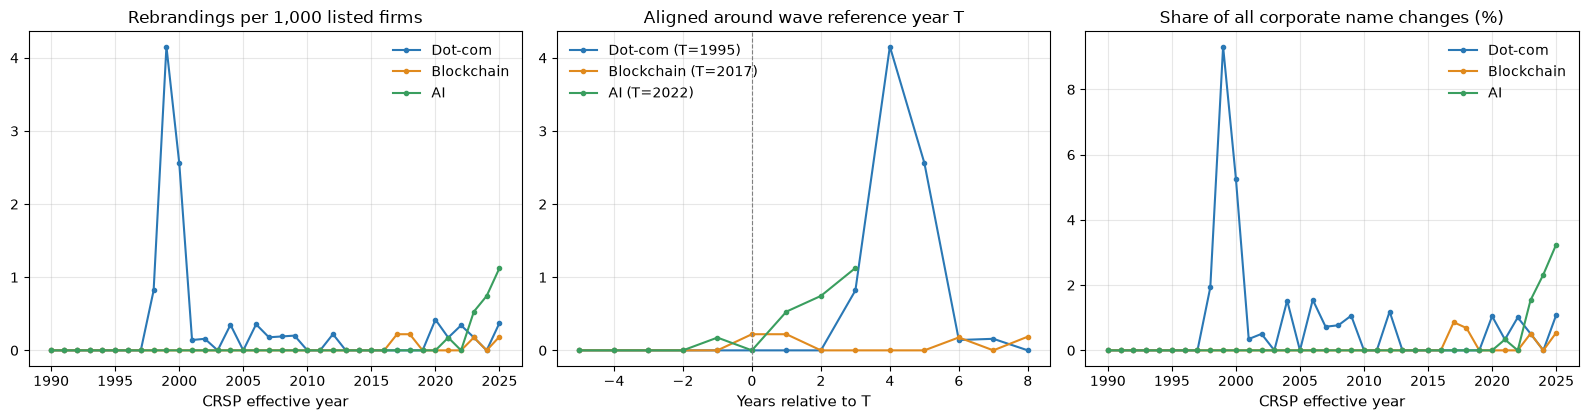

,theme,wave_period,wave_years,events_all_years,events_in_wave,events_outside_wave,in_wave_de_spac_closings,in_wave_former_spacs,avg_intensity_per_1000_per_year,peak_year,peak_intensity_per_1000,share_of_all_name_changes_pct
0,Dot-com,1995-2002,8,79,63,16,0,0,0.98,1999,4.15,2.49
1,Blockchain,2016-2020,5,4,2,2,0,0,0.09,2017,0.22,0.28
2,AI,2021-2025,5,14,14,0,5,8,0.52,2025,1.13,1.33


In [6]:
def build_theme_year(events, listed, all_changes):
    """
    Build the theme x year panel with counts, intensity per 1,000 listed firms and thematic share.

    Parameters
    ----------
    events, listed, all_changes : pandas.DataFrame

    Returns
    -------
    pandas.DataFrame
        One row per theme and year (1990-2025), incl. ``relative_year`` = year - T_k.
    """
    grid = pd.MultiIndex.from_product([themes, range(study_start_year, study_end_year + 1)],
                                      names=["theme", "year"]).to_frame(index=False)
    counts = (events.assign(year=events["effective_date"].dt.year)
              .groupby(["theme", "year"]).size().rename("thematic_rebrandings").reset_index())
    per_year = all_changes.groupby("year").size().rename("all_name_changes").reset_index()
    panel = grid.merge(counts, on=["theme", "year"], how="left").merge(listed, on="year", how="left") \
                .merge(per_year, on="year", how="left")
    panel["thematic_rebrandings"] = panel["thematic_rebrandings"].fillna(0).astype(int)
    panel["intensity_per_1000"] = panel["thematic_rebrandings"] / panel["listed_firms"] * 1000
    panel["thematic_share_pct"] = panel["thematic_rebrandings"] / panel["all_name_changes"] * 100
    panel["relative_year"] = panel["year"] - panel["theme"].map(wave_reference_year)
    return panel


def summarise_waves(panel, events):
    """
    Summarise prevalence per wave period (effective-year counts).

    Parameters
    ----------
    panel : pandas.DataFrame
    events : pandas.DataFrame

    Returns
    -------
    pandas.DataFrame
        One row per theme.
    """
    rows = []
    for theme in themes:
        first, last = wave_periods[theme]
        wave = panel[(panel["theme"] == theme) & panel["year"].between(first, last)]
        theme_events = events[(events["theme"] == theme) & (events["in_wave_effective_year"] == 1)]
        rows.append({
            "theme": theme, "wave_period": f"{first}-{last}", "wave_years": last - first + 1,
            "events_all_years": int((events["theme"] == theme).sum()),
            "events_in_wave": int(wave["thematic_rebrandings"].sum()),
            "events_outside_wave": int((events["theme"] == theme).sum() - wave["thematic_rebrandings"].sum()),
            "in_wave_de_spac_closings": int((theme_events["deal_type"] == "d").sum()),
            "in_wave_former_spacs": int(theme_events["former_spac"].sum()),
            "avg_intensity_per_1000_per_year": wave["intensity_per_1000"].mean(),
            "peak_year": int(wave.loc[wave["intensity_per_1000"].idxmax(), "year"]),
            "peak_intensity_per_1000": wave["intensity_per_1000"].max(),
            "share_of_all_name_changes_pct": wave["thematic_rebrandings"].sum() / wave["all_name_changes"].sum() * 100,
        })
    return pd.DataFrame(rows)


def plot_prevalence(panel):
    """
    Plot thematic rebranding intensity in calendar time and aligned around T_k.

    Parameters
    ----------
    panel : pandas.DataFrame
    """
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
    for theme in themes:
        sub = panel[panel["theme"] == theme]
        style = dict(marker="o", ms=3, color=theme_colors[theme])
        axes[0].plot(sub["year"], sub["intensity_per_1000"], label=theme, **style)
        aligned = sub[sub["relative_year"].between(-5, 8)]
        axes[1].plot(aligned["relative_year"], aligned["intensity_per_1000"],
                     label=f"{theme} (T={wave_reference_year[theme]})", **style)
        axes[2].plot(sub["year"], sub["thematic_share_pct"], label=theme, **style)
    axes[0].set(title="Rebrandings per 1,000 listed firms", xlabel="CRSP effective year")
    axes[1].set(title="Aligned around wave reference year T", xlabel="Years relative to T")
    axes[1].axvline(0, color="grey", lw=0.8, ls="--")
    axes[2].set(title="Share of all corporate name changes (%)", xlabel="CRSP effective year")
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(output_dir / "rq1_rebranding_prevalence.png", dpi=150)
    plt.show()


theme_year = build_theme_year(events, listed, all_changes)
wave_summary = summarise_waves(theme_year, events)
plot_prevalence(theme_year)
wave_summary.round(2)

## Step 6: Pre-event firm characteristics
* **Compustat** (via CCM links LU/LC, primary P/C, valid on the fiscal-year-end date): the latest fiscal year
  whose accounts were **public before the event**, i.e. fiscal year end at least 6 months (182 days) before the
  event date, and not older than two further years. The 6-month lag follows Fama & French (1992). There is **no
  post-event fallback**. Missing stays missing.
  Variables: log assets, sales growth, ROA, R&D/assets, CAPEX/assets, leverage, cash/assets,
  intangibles/assets, winsorised at 1%/99% (Tutorial 4).
* **CRSP** (`es.build_crsp_characteristics`): log market cap and price on the last trading day on or before
  day −30, and the return volatility and buy-and-hold return over [−250, −30] (at least 20 returns). Firms
  without pre-event trading get missing values.

In [7]:
ratio_columns = ["sales_growth", "roa", "rd_to_assets", "capex_to_assets", "leverage",
                 "cash_to_assets", "intangibles_to_assets"]
compustat_columns = ["log_assets"] + ratio_columns
crsp_columns = ["log_market_cap", "price", "penny_stock", "pre_event_volatility", "pre_event_return"]


def winsorize(series, lower=0.01, upper=0.99):
    """
    Clip a series at its 1st and 99th percentiles.

    Parameters
    ----------
    series : pandas.Series
    lower, upper : float

    Returns
    -------
    pandas.Series
    """
    return series.clip(series.quantile(lower), series.quantile(upper))


def build_compustat_panel(compustat, ccm):
    """
    Build CRSP-linked Compustat firm-years with size and ratio variables.

    Parameters
    ----------
    compustat : pandas.DataFrame
        ``comp.funda`` extract.
    ccm : pandas.DataFrame
        ``ccmxpf_lnkhist`` extract.

    Returns
    -------
    pandas.DataFrame
        Firm-years with ``permno`` and the Compustat characteristics.
    """
    fund = compustat.copy()
    fund["datadate"] = pd.to_datetime(fund["datadate"])
    fund = fund.sort_values(["gvkey", "datadate"]).drop_duplicates(["gvkey", "fyear"], keep="last")
    assets = fund["at"].where(fund["at"] > 0)
    fund["log_assets"] = np.log(assets)
    fund["roa"] = fund["ib"] / assets
    fund["rd_to_assets"] = fund["xrd"] / assets
    fund["capex_to_assets"] = fund["capx"] / assets
    fund["leverage"] = (fund["dlc"].fillna(0) + fund["dltt"].fillna(0)) / assets
    fund["cash_to_assets"] = fund["che"] / assets
    fund["intangibles_to_assets"] = fund["intan"] / assets
    lag = fund[["gvkey", "fyear", "sale"]].assign(fyear=fund["fyear"] + 1).rename(columns={"sale": "sale_lag"})
    fund = fund.merge(lag, on=["gvkey", "fyear"], how="left")
    fund["sales_growth"] = fund["sale"] / fund["sale_lag"].where(fund["sale_lag"] > 0) - 1

    links = ccm[ccm["linktype"].isin(["LU", "LC"]) & ccm["linkprim"].isin(["P", "C"])].copy()
    links["link_start"] = pd.to_datetime(links["linkdt"])
    links["link_end"] = pd.to_datetime(links["linkenddt"]).fillna(pd.Timestamp("2099-12-31"))
    fund = fund.merge(links[["gvkey", "lpermno", "link_start", "link_end"]], on="gvkey")
    fund = fund[fund["datadate"].between(fund["link_start"], fund["link_end"])]
    fund = fund.rename(columns={"lpermno": "permno"}).drop_duplicates(["permno", "datadate"])
    for column in ratio_columns:
        fund[column] = winsorize(fund[column].replace([np.inf, -np.inf], np.nan))
    return fund[["gvkey", "permno", "datadate", "fyear", "sic", "sich"] + compustat_columns]


def match_event_fundamentals(events, firm_years):
    """
    Attach the latest fiscal year that was public before each event (6-month reporting lag, no fallback).

    Parameters
    ----------
    events : pandas.DataFrame
    firm_years : pandas.DataFrame

    Returns
    -------
    pandas.DataFrame
        ``event_id``, ``fundamentals_fyear``, ``fundamentals_timing`` and the Compustat characteristics.
    """
    rows = []
    for event in events.itertuples():
        firm = firm_years[firm_years["permno"] == event.permno]
        public_from = firm["datadate"] + pd.Timedelta(days=reporting_lag_days)
        age = (event.event_date - public_from).dt.days
        usable = firm[age.between(0, max_fundamentals_age_days)]
        if usable.empty:
            rows.append({"event_id": event.event_id, "fundamentals_timing": "missing"})
            continue
        chosen = usable.loc[usable["datadate"].idxmax()]
        rows.append({"event_id": event.event_id, "fundamentals_timing": "pre (6-month lag)",
                     "fundamentals_fyear": chosen["fyear"], **chosen[compustat_columns].to_dict()})
    return pd.DataFrame(rows)


def assign_event_industry(events, firm_years):
    """
    Classify each rebranding firm into a Fama-French 12 industry.

    The CRSP SIC code on the event date is used, except for SPAC shells (SIC 6770/6799) and missing or 9999
    codes. For those, the historical Compustat SIC (``sich``) of the first fiscal year after the event
    describes the operating business (the merged company); the Compustat header SIC is the last fallback.
    Industry is a descriptive characteristic, so using a post-event code here is allowed; it is never used
    as a pre-event explanatory variable of returns.

    Parameters
    ----------
    events : pandas.DataFrame
    firm_years : pandas.DataFrame

    Returns
    -------
    pandas.DataFrame
        ``event_id``, ``industry_sic``, ``industry_sic_source`` and ``industry`` (FF12 label).
    """
    rows = []
    for event in events.itertuples():
        sic, source = event.siccd, "CRSP SIC on the event date"
        if pd.isna(sic) or int(sic) in es.SPAC_SIC_CODES or int(sic) == 9999:
            firm = firm_years[(firm_years["permno"] == event.permno) & (firm_years["datadate"] >= event.event_date)]
            firm = firm.sort_values("datadate")
            historical = firm["sich"].dropna()
            historical = historical[~historical.astype(int).isin(es.SPAC_SIC_CODES)]
            header = firm["sic"].dropna()
            if len(historical):
                sic, source = historical.iloc[0], "Compustat SIC of the first fiscal year after the event"
            elif len(header):
                sic, source = header.iloc[0], "Compustat header SIC"
            else:
                source = "no operating-business SIC found"
        rows.append({"event_id": event.event_id, "industry_sic": sic, "industry_sic_source": source,
                     "industry": es.ff12_industry(sic) if source != "no operating-business SIC found" else "Unclassified"})
    return pd.DataFrame(rows)


firm_years = build_compustat_panel(raw["compustat"], raw["ccm"])
event_firms = (events.merge(match_event_fundamentals(events, firm_years), on="event_id", how="left")
               .merge(es.build_crsp_characteristics(events, daily, market), on="event_id", how="left")
               .merge(assign_event_industry(events, firm_years), on="event_id", how="left"))
print("industry SIC source:", event_firms["industry_sic_source"].value_counts().to_dict())
print("fundamentals timing:", event_firms["fundamentals_timing"].value_counts().to_dict())
print("CRSP size available:", int(event_firms["log_market_cap"].notna().sum()), "of", len(event_firms))
event_firms.groupby("theme")[compustat_columns + crsp_columns].median().reindex(themes).T.round(3)

industry SIC source: {'CRSP SIC on the event date': 84, 'Compustat SIC of the first fiscal year after the event': 12, 'no operating-business SIC found': 1}
fundamentals timing: {'pre (6-month lag)': 76, 'missing': 21}
CRSP size available: 94 of 97


theme,Dot-com,Blockchain,AI
log_assets,3.436,2.052,2.780
sales_growth,0.230,-0.465,-0.381
roa,-0.163,-1.342,-1.317
rd_to_assets,0.126,0.051,0.156
capex_to_assets,0.029,0.002,0.006
leverage,0.063,0.178,0.214
cash_to_assets,0.378,0.565,0.061
intangibles_to_assets,0.011,0.003,0.000
log_market_cap,11.010,9.978,10.699
price,5.000,3.015,3.018


## Step 7: Exploratory data analysis of the event sample
Following Tutorial 4 (`describe`, histograms, correlation matrix, `scatter_matrix`), we look for data features
that matter for the event study:
* **Fat tails:** daily returns of small listed firms are far from normal, so the t-test is complemented by a
  sign test, BMP and the bootstrap.
* **Penny stocks and size:** how small are the rebranders?
* **Correlations** between firm characteristics: which controls overlap (multicollinearity in RQ3)?

In [8]:
event_firms[compustat_columns + crsp_columns].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
log_assets,75.0,3.387,1.498,0.306,2.165,3.278,4.308,7.511
sales_growth,69.0,0.585,1.251,-0.855,-0.192,0.204,0.955,5.504
roa,75.0,-0.419,0.519,-1.771,-0.684,-0.211,-0.040,0.162
rd_to_assets,43.0,0.186,0.228,0.000,0.036,0.123,0.262,1.014
capex_to_assets,74.0,0.040,0.064,0.000,0.005,0.027,0.047,0.358
leverage,75.0,0.203,0.268,0.000,0.000,0.079,0.288,1.014
cash_to_assets,75.0,0.383,0.306,0.001,0.051,0.380,0.664,0.943
intangibles_to_assets,67.0,0.144,0.211,0.000,0.000,0.008,0.221,0.742
log_market_cap,94.0,11.014,1.469,7.633,10.008,10.920,11.958,15.312
price,94.0,8.266,14.191,0.159,2.015,4.812,10.060,108.938


event firms: sd = 0.081, skew = 8.33, excess kurtosis = 346.4
market (vw): sd = 0.011, skew = -0.27, excess kurtosis = 10.5


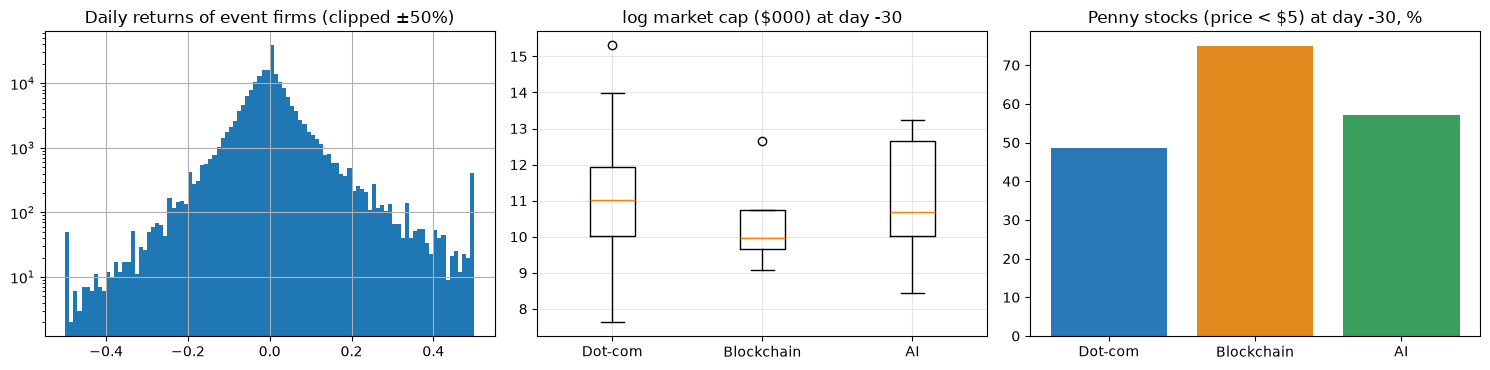

In [9]:
# Daily returns of the event firms: fat tails (kurtosis) vs. the market index
event_returns = daily.loc[daily["permno"].isin(events["permno"]), "dlyret"].dropna()
market_returns = market.loc[market["date"].dt.year.between(1990, 2025), "market_return"]
print(f"event firms: sd = {event_returns.std():.3f}, skew = {event_returns.skew():.2f}, "
      f"excess kurtosis = {event_returns.kurt():.1f}")
print(f"market (vw): sd = {market_returns.std():.3f}, skew = {market_returns.skew():.2f}, "
      f"excess kurtosis = {market_returns.kurt():.1f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
event_returns.clip(-0.5, 0.5).hist(bins=100, ax=axes[0])
axes[0].set(title="Daily returns of event firms (clipped ±50%)", yscale="log")
axes[1].boxplot([event_firms.loc[event_firms["theme"] == t, "log_market_cap"].dropna() for t in themes])
axes[1].set_xticks(range(1, len(themes) + 1), themes)       # same wave order as the other panels
axes[1].set(title="log market cap ($000) at day -30")
axes[1].grid(alpha=0.3)
penny = event_firms.groupby("theme")["penny_stock"].mean().reindex(themes) * 100
axes[2].bar(penny.index, penny.values, color=[theme_colors[t] for t in penny.index])
axes[2].set(title="Penny stocks (price < $5) at day -30, %")
fig.tight_layout()
fig.savefig(output_dir / "eda_event_sample.png", dpi=150)
plt.show()

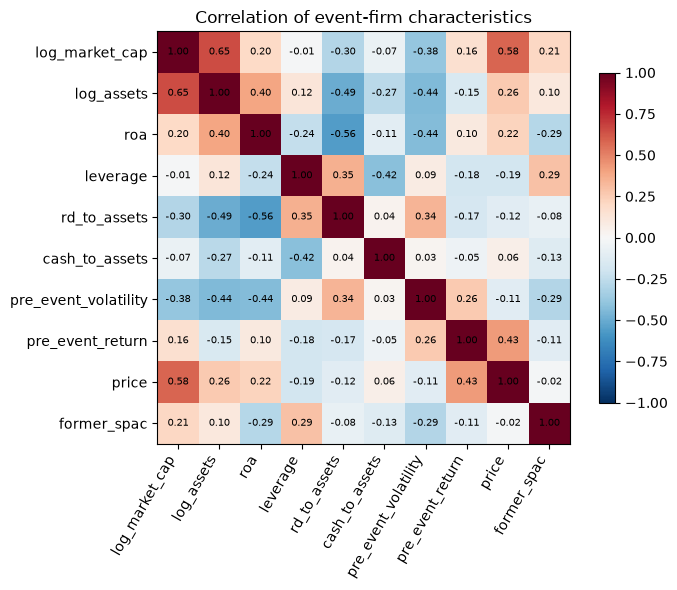

In [10]:
# Correlation matrix of pre-event firm characteristics (as in Tutorial 4)
eda_columns = ["log_market_cap", "log_assets", "roa", "leverage", "rd_to_assets", "cash_to_assets",
               "pre_event_volatility", "pre_event_return", "price", "former_spac"]
corr_matrix = event_firms[eda_columns].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(7.5, 6))
image = ax.imshow(corr_matrix, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(eda_columns)), eda_columns, rotation=60, ha="right")
ax.set_yticks(range(len(eda_columns)), eda_columns)
for i in range(len(eda_columns)):
    for j in range(len(eda_columns)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, shrink=0.8)
ax.set_title("Correlation of event-firm characteristics")
fig.tight_layout()
fig.savefig(output_dir / "eda_correlation_matrix.png", dpi=150)
plt.show()

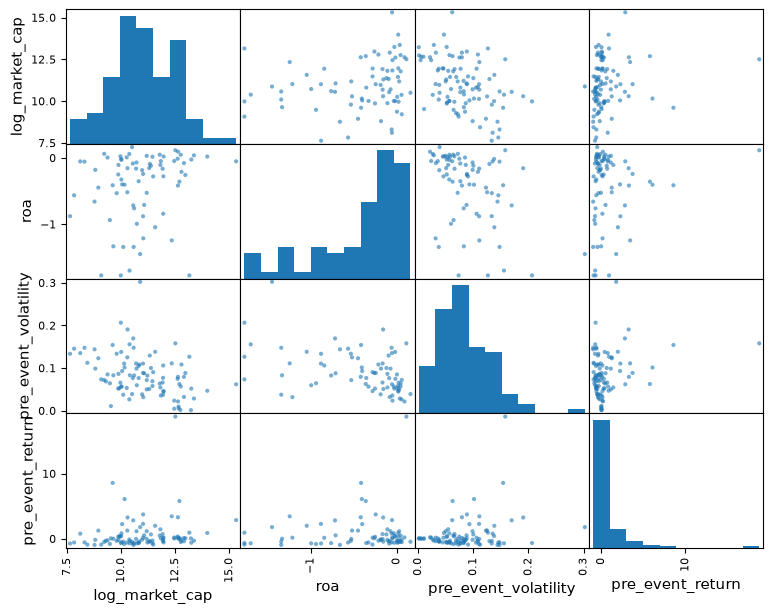

In [11]:
scatter_matrix(event_firms[["log_market_cap", "roa", "pre_event_volatility", "pre_event_return"]],
               figsize=(9, 7), alpha=0.6)
plt.show()

## Step 8: RQ2, announcement response
**Abnormal returns** (`es.compute_abnormal_returns`). Day 0 = the first market session that can react to the
public announcement (after-close news → next session). Market model with the CRSP value-weighted index over
sessions [−250, −30]; events with fewer than 60 estimation days use the market-adjusted model and are marked
*descriptive only*. A CAR needs a **complete** window.
$$AR_{i,t} = R_{i,t} - (\hat\alpha_i + \hat\beta_i R_{m,t}), \qquad CAR_i[\tau_1,\tau_2] = \sum_{t=\tau_1}^{\tau_2} AR_{i,t}$$
**Abnormal volume** = log(1 + volume) minus its pre-event mean (needs 20 pre-event days), summed over the window.

**Declared analysis (fixed before looking at any returns):**
* primary outcome **mean CAR[−1,+1]**; secondary: CAR[−5,+5] and abnormal volume CAV[−1,+1];
* primary sample: grade A/B dates, wave years, deal types a/b;
* Dot-com is the main inferential test; AI is reported with its interval (small n); the two in-wave Blockchain
  events are **case studies**;
* reported together: n, mean, median, % positive, 95% CI, minimum detectable effect (80% power), t-test,
  **sign test** (median = 0 under skewness), Wilcoxon, BMP (Boehmer et al., 1991),
  bootstrap (n ≥ 10), and a **t-test clustered by event month** (≥ 10 months; Kolari & Pynnönen, 2010, show
  that cross-correlated events inflate ordinary t-tests).

In [12]:
abnormal, estimates, residuals = es.compute_abnormal_returns(events, daily, market, "market_model", "event_date",
                                                             timing_column="announcement_timing")
cars = es.compute_cars(abnormal, estimates, events).merge(events[["event_id", "event_month"]], on="event_id")
primary = cars[cars["primary_sample"] == 1]
print("dropped:", estimates.loc[estimates["dropped_reason"] != "", ["event_id", "dropped_reason"]].to_dict("records"))
print("benchmark used:", estimates["benchmark_used"].value_counts().to_dict(),
      "| descriptive only (< 60 days):", int(estimates["descriptive_only"].fillna(False).sum()))

dropped: [{'event_id': 53, 'dropped_reason': 'no trade within 2 sessions of day 0'}]
benchmark used: {'market_model': 91, 'market_adjusted': 5} | descriptive only (< 60 days): 5


In [13]:
def extend_sample_flow(events, cars):
    """
    Continue the notebook-02 sample flow with the valid return windows of the primary sample.

    Parameters
    ----------
    events, cars : pandas.DataFrame

    Returns
    -------
    pandas.DataFrame
        One row per step, one column per wave.
    """
    flow = pd.read_excel(event_dates_out_dir / "event_register.xlsx", sheet_name="sample_flow")
    primary_cars = cars[cars["primary_sample"] == 1]
    extra = [("... with a complete CAR[-1,+1] window", primary_cars.dropna(subset=["car_m1_p1"])),
             ("... with a complete CAR[-5,+5] window", primary_cars.dropna(subset=["car_m5_p5"])),
             ("... with abnormal volume CAV[-1,+1] (pre-event volume baseline)", primary_cars.dropna(subset=["cav_m1_p1"])),
             ("... with a market-model benchmark (>= 60 estimation days)",
              primary_cars[(primary_cars["descriptive_only"] == False) & primary_cars["car_m1_p1"].notna()])]
    rows = [{"step": label, **sub.groupby("theme").size().reindex(themes).fillna(0).astype(int).to_dict(),
             "total": len(sub)} for label, sub in extra]
    return pd.concat([flow, pd.DataFrame(rows)], ignore_index=True)


sample_flow = extend_sample_flow(events, cars)
sample_flow

,step,Dot-com,Blockchain,AI,total
0,detected thematic renames (all years),79,4,14,97
1,inside the wave period,63,2,14,79
2,... with a public announcement date (grade A o...,49,2,14,65
3,... and deal type a or b (primary sample),39,2,8,49
4,"... with a complete CAR[-1,+1] window",37,2,8,47
5,"... with a complete CAR[-5,+5] window",37,2,8,47
6,"... with abnormal volume CAV[-1,+1] (pre-event...",37,2,8,47
7,... with a market-model benchmark (>= 60 estim...,36,2,8,46


In [14]:
measures = [es.PRIMARY_MEASURE] + es.SECONDARY_MEASURES + ["car_m10_p10"]
samples = {f"{t} (primary)": (lambda d, t=t: (d["theme"] == t) & (d["primary_sample"] == 1)) for t in themes}
samples["Dot-com + AI (primary)"] = lambda d: d["theme"].isin(["Dot-com", "AI"]) & (d["primary_sample"] == 1)
event_study_summary = es.summarise_event_study(cars, samples, measures)
event_study_summary[event_study_summary["measure"].isin([es.PRIMARY_MEASURE] + es.SECONDARY_MEASURES)].round(4)

,sample,measure,n,mean,median,pct_positive,ci_low,ci_high,mde_80,t_pvalue,sign_pvalue,wilcoxon_pvalue,n_bmp,bmp_t,bmp_pvalue,boot_ci_low,boot_ci_high,boot_pvalue,n_clusters,cluster_pvalue
0,Dot-com (primary),car_m1_p1,37,0.0869,0.0663,62.1622,-0.0014,0.1751,0.1253,0.0534,0.1877,0.0473,37.0,1.6712,0.1034,0.0078,0.1738,0.0410,22.0,0.0218
1,Dot-com (primary),car_m5_p5,37,0.1659,0.0366,64.8649,0.0545,0.2774,0.1583,0.0046,0.0989,0.0152,37.0,3.1655,0.0031,0.0655,0.2768,0.0031,22.0,0.0005
2,Dot-com (primary),cav_m1_p1,37,4.1596,3.4408,91.8919,2.7225,5.5967,2.0407,0.0000,0.0000,0.0000,NaN,NaN,NaN,2.8614,5.6136,0.0000,22.0,0.0000
4,Blockchain (primary),car_m1_p1,2,1.0131,1.0131,100.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Blockchain (primary),car_m5_p5,2,1.3405,1.3405,100.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Blockchain (primary),cav_m1_p1,2,11.3356,11.3356,100.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,AI (primary),car_m1_p1,8,0.0423,0.0254,62.5000,-0.1215,0.2061,0.2259,0.5604,0.7266,0.6406,8.0,0.8745,0.4108,NaN,NaN,NaN,8.0,NaN
9,AI (primary),car_m5_p5,8,-0.0264,-0.1429,37.5000,-0.2690,0.2163,0.3346,0.8046,0.7266,0.8438,8.0,0.2193,0.8327,NaN,NaN,NaN,8.0,NaN
10,AI (primary),cav_m1_p1,8,4.5169,3.9151,87.5000,0.9696,8.0643,4.8916,0.0196,0.0703,0.0156,NaN,NaN,NaN,NaN,NaN,NaN,8.0,NaN
12,Dot-com + AI (primary),car_m1_p1,45,0.0789,0.0622,62.2222,0.0031,0.1548,0.1078,0.0416,0.1352,0.0489,45.0,1.9058,0.0632,0.0098,0.1541,0.0320,30.0,0.0177


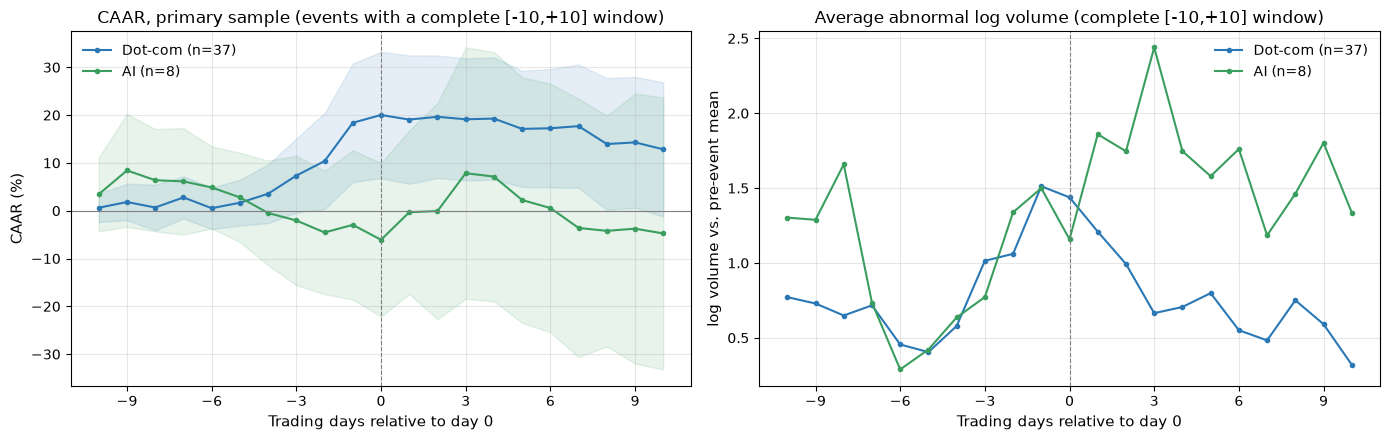

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
es.plot_caar(abnormal, primary[primary["theme"] != "Blockchain"], "theme", theme_colors, axes[0],
             title="CAAR, primary sample (events with a complete [-10,+10] window)")
volume = abnormal.merge(primary.dropna(subset=["cav_m10_p10"])[["event_id", "theme"]], on="event_id")
for theme in ["Dot-com", "AI"]:
    path = volume[volume["theme"] == theme].groupby("relative_day")["abnormal_volume"].mean()
    n = volume.loc[volume["theme"] == theme, "event_id"].nunique()
    axes[1].plot(path.index, path, marker="o", ms=3, color=theme_colors[theme], label=f"{theme} (n={n})")
axes[1].set(title="Average abnormal log volume (complete [-10,+10] window)", ylabel="log volume vs. pre-event mean",
            xlabel="Trading days relative to day 0")
axes[1].axvline(0, color="grey", lw=0.8, ls="--")
axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].grid(alpha=0.3)
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(output_dir / "rq2_event_study_caar.png", dpi=150)
plt.show()

### Precision: what the small samples can and cannot tell us
`ci_low`/`ci_high` is the t-based 95% interval of the mean CAR and `mde_80` the minimum detectable effect,
$MDE = (t_{0.975,n-1} + t_{0.80,n-1})\cdot sd/\sqrt{n}$. Both are approximate: the interval concerns the
population mean under the sampling model, and the MDE is a sensitivity calculation, not proof of adequate power.
A non-significant AI result with a wide interval is **not evidence of no effect**.

In [16]:
precision = event_study_summary[["sample", "measure", "n", "mean", "median", "ci_low", "ci_high", "mde_80",
                                 "boot_ci_low", "boot_ci_high", "n_clusters"]]
precision[precision["measure"].isin([es.PRIMARY_MEASURE, "car_m5_p5"])].round(4)

,sample,measure,n,mean,median,ci_low,ci_high,mde_80,boot_ci_low,boot_ci_high,n_clusters
0,Dot-com (primary),car_m1_p1,37,0.0869,0.0663,-0.0014,0.1751,0.1253,0.0078,0.1738,22.0
1,Dot-com (primary),car_m5_p5,37,0.1659,0.0366,0.0545,0.2774,0.1583,0.0655,0.2768,22.0
4,Blockchain (primary),car_m1_p1,2,1.0131,1.0131,NaN,NaN,NaN,NaN,NaN,NaN
5,Blockchain (primary),car_m5_p5,2,1.3405,1.3405,NaN,NaN,NaN,NaN,NaN,NaN
8,AI (primary),car_m1_p1,8,0.0423,0.0254,-0.1215,0.2061,0.2259,NaN,NaN,8.0
9,AI (primary),car_m5_p5,8,-0.0264,-0.1429,-0.2690,0.2163,0.3346,NaN,NaN,8.0
12,Dot-com + AI (primary),car_m1_p1,45,0.0789,0.0622,0.0031,0.1548,0.1078,0.0098,0.1541,30.0
13,Dot-com + AI (primary),car_m5_p5,45,0.1317,0.0352,0.0319,0.2315,0.1419,0.0391,0.2320,30.0


### Blockchain case studies (single-firm tests)
The two in-wave Blockchain renames (Riot Blockchain 2017, Long Blockchain 2017) are the case studies; Bitcoin
Depot (2022–23, de-SPAC) and American Bitcoin (2025, reverse merger) fall outside the 2016–2020 wave and are
shown as a labelled appendix. Each event is tested on its own with
* the standardised CAR (SCAR, t-distribution with T − 2 degrees of freedom), and
* the **SQ test** of Gelbach, Helland & Klick (2013): the share of all same-length windows in the firm's own
  pre-event abnormal returns that are at least as extreme as the event CAR. It does not assume normal returns,
  which matters for single-firm inference.
Results are reported **per window**; a firm is not called "significant" by mixing windows.

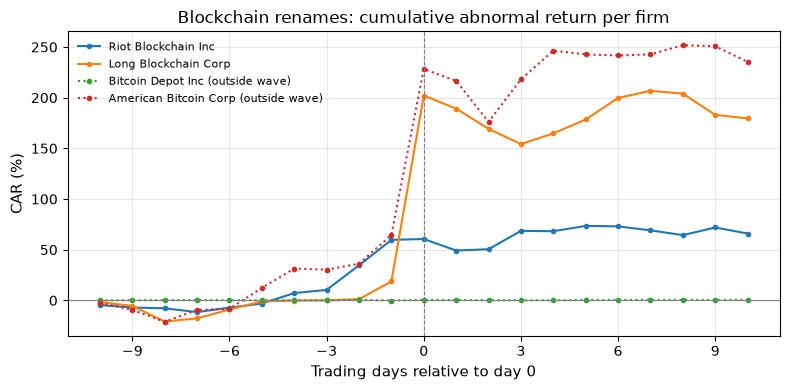

/var/folders/yw/m16m81nx1sgfh87b0fr84w440000gn/T/ipykernel_56182/1476539968.py:49: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  blockchain_cases.round(4)


,event_id,new_name,event_date,deal_type,in_wave,window,car,scar,scar_pvalue,sq_pvalue,sq_windows
0,72,RIOT BLOCKCHAIN INC,2017-10-04,b,1,car_m1_p1,0.1457,1.6132,0.1081,0.0320,219
1,72,RIOT BLOCKCHAIN INC,2017-10-04,b,1,car_m5_p5,0.8063,4.5741,0.0000,0.0000,211
2,72,RIOT BLOCKCHAIN INC,2017-10-04,b,1,car_m10_p10,0.6598,2.6580,0.0084,0.0000,201
3,73,LONG BLOCKCHAIN CORP,2017-12-21,b,1,car_m1_p1,1.8805,28.7745,0.0000,0.0000,219
4,73,LONG BLOCKCHAIN CORP,2017-12-21,b,1,car_m5_p5,1.8748,14.7208,0.0000,0.0000,211
5,73,LONG BLOCKCHAIN CORP,2017-12-21,b,1,car_m10_p10,1.7954,9.9370,0.0000,0.0000,201
6,81,BITCOIN DEPOT INC,2022-08-25,d,0,car_m1_p1,-0.0018,-0.1069,0.9153,0.5172,58
7,81,BITCOIN DEPOT INC,2022-08-25,d,0,car_m5_p5,0.0017,0.0490,0.9611,0.7800,50
8,81,BITCOIN DEPOT INC,2022-08-25,d,0,car_m10_p10,0.0052,0.1027,0.9186,0.4000,40
9,93,AMERICAN BITCOIN CORP,2025-05-12,c,0,car_m1_p1,1.8049,15.2940,0.0000,0.0000,219


In [17]:
def single_event_tests(cars, estimates, residuals, theme):
    """
    Test each event of one wave individually (SCAR t-test and SQ test) for every window.

    Parameters
    ----------
    cars, estimates : pandas.DataFrame
    residuals : dict
        Pre-event abnormal returns per event (from :func:`es.compute_abnormal_returns`).
    theme : str

    Returns
    -------
    pandas.DataFrame
        One row per event and window.
    """
    data = cars[cars["theme"] == theme].merge(estimates[["event_id", "estimation_days"]], on="event_id", how="left")
    rows = []
    for event in data.itertuples():
        dof = max(int(event.estimation_days) - 2, 10)
        for window, (start, end) in es.CAR_WINDOWS.items():
            car, scar = getattr(event, window), getattr(event, window.replace("car", "scar"))
            sq_p, sq_n = es.sq_test(car, residuals.get(event.event_id, []), end - start + 1)
            rows.append({"event_id": event.event_id, "new_name": event.new_name, "event_date": event.event_date,
                         "deal_type": event.deal_type, "in_wave": event.in_wave_period, "window": window,
                         "car": car, "scar": scar, "scar_pvalue": 2 * stats.t.sf(abs(scar), dof) if pd.notna(scar) else np.nan,
                         "sq_pvalue": sq_p, "sq_windows": sq_n})
    return pd.DataFrame(rows)


blockchain_cases = single_event_tests(cars, estimates, residuals, "Blockchain")
fig, ax = plt.subplots(figsize=(8, 4))
for event_id, group in abnormal[abnormal["event_id"].isin(blockchain_cases["event_id"])].groupby("event_id"):
    info = blockchain_cases[blockchain_cases["event_id"] == event_id].iloc[0]
    path = group.sort_values("relative_day")
    label = f"{info['new_name'].title()}{'' if info['in_wave'] else ' (outside wave)'}"
    ax.plot(path["relative_day"], path["abnormal_return"].cumsum() * 100, marker="o", ms=3, label=label,
            ls="-" if info["in_wave"] else ":")
ax.axvline(0, color="grey", lw=0.8, ls="--")
ax.axhline(0, color="grey", lw=0.8)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set(title="Blockchain renames: cumulative abnormal return per firm", xlabel="Trading days relative to day 0",
       ylabel="CAR (%)")
ax.legend(frameon=False, fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(output_dir / "rq2_blockchain_case_studies.png", dpi=150)
plt.show()
blockchain_cases.round(4)

### Influence checks (not data cleaning)
Extreme returns are kept: they are real prices of small firms. Instead we show how much single events move the
mean (leave-one-out). The IsolationForest of Tutorial 4 is run on the outcomes and flags 5% of the events; because
it is trained on the outcomes, re-estimating without them shows **influence**, not data errors, and is not used
as evidence for the headline.

In [18]:
loo_dotcom = es.leave_one_out(primary[primary["theme"] == "Dot-com"], es.PRIMARY_MEASURE)
loo_ai = es.leave_one_out(primary[primary["theme"] == "AI"], es.PRIMARY_MEASURE)
print("Dot-com: range of the mean when one event is dropped:",
      round(loo_dotcom["mean_without"].min(), 4), "to", round(loo_dotcom["mean_without"].max(), 4))
print("AI: range of the mean when one event is dropped:",
      round(loo_ai["mean_without"].min(), 4), "to", round(loo_ai["mean_without"].max(), 4))
pd.concat([loo_dotcom.head(3).assign(theme="Dot-com"), loo_dotcom.tail(3).assign(theme="Dot-com"),
           loo_ai.head(2).assign(theme="AI"), loo_ai.tail(2).assign(theme="AI")]).round(4)

Dot-com: range of the mean when one event is dropped: 0.0637 to 0.1013
AI: range of the mean when one event is dropped: -0.0165 to 0.0822


,event_id,new_name,car_m1_p1,mean_without,change_in_mean,theme
17,29,GETGO MAIL COM INC,0.9204,0.0637,-0.0232,Dot-com
10,14,FINET COM INC,0.6725,0.0706,-0.0163,Dot-com
3,5,INTERNET COMMERCE CORP,0.6697,0.0707,-0.0162,Dot-com
33,57,CLICKNSETTLE COM INC,-0.2954,0.0975,0.0106,Dot-com
22,38,ILIFE COM INC,-0.3257,0.0983,0.0115,Dot-com
6,9,EFAX COM INC,-0.4319,0.1013,0.0144,Dot-com
2,87,PALLADYNE AI CORP,0.4541,-0.0165,-0.0588,AI
5,90,SUPER X AI TECHNOLOGY LTD,0.0963,0.0346,-0.0077,AI
7,97,MICROPOLIS AI ROBOTICS,-0.0735,0.0589,0.0165,AI
0,85,GAXOS AI INC,-0.2370,0.0822,0.0399,AI


## Step 9: RQ4, firm characteristics of the adopters
**Unit of comparison:** one pre-event observation per rebranding event (its matched fiscal year from
Step 6) against **non-rebranding firms in the same fiscal years**. Each event's fiscal year gets the same total
weight, so a wave's controls mirror the timing of its events. We report the medians and the **standardised
difference** (difference in means divided by the pooled standard deviation; |d| > 0.1 is usually read as a
meaningful imbalance, Austin, 2009) before any p-value. The Mann-Whitney U p-value tests whether one
distribution tends to lie above the other (it is not a test of equal medians).
All in-wave thematic renames are used here (any date grade or deal type): RQ4 asks which firms adopt the
buzzword, not how the market reacts.

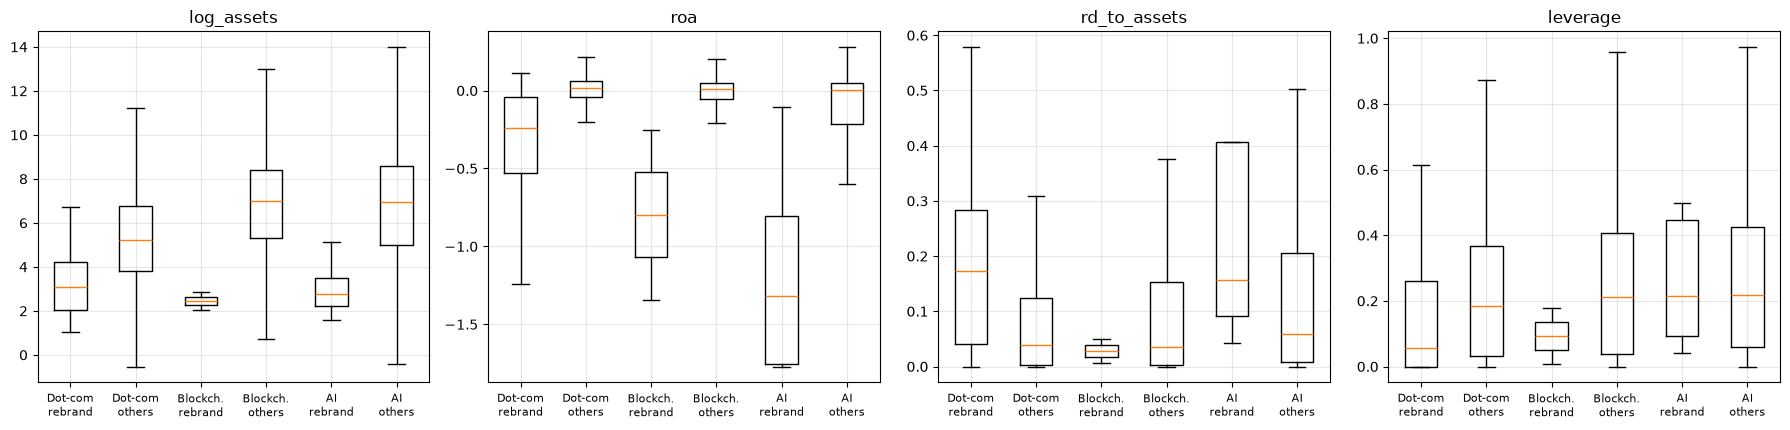

,comparison,characteristic,n_rebranders,median_rebranders,n_control_firm_years,median_control,std_difference,p_value,test,median_Dot-com,median_Blockchain,median_AI,n_Dot-com,n_Blockchain,n_AI
0,Dot-com rebranders vs. same-year non-rebranders,log_assets,51.0,3.064,38794.0,5.242,-1.146,0.000,Mann-Whitney U,NaN,NaN,NaN,NaN,NaN,NaN
1,Dot-com rebranders vs. same-year non-rebranders,sales_growth,48.0,0.353,37629.0,0.129,0.334,0.096,Mann-Whitney U,NaN,NaN,NaN,NaN,NaN,NaN
2,Dot-com rebranders vs. same-year non-rebranders,roa,51.0,-0.243,38716.0,0.017,-0.827,0.000,Mann-Whitney U,NaN,NaN,NaN,NaN,NaN,NaN
3,Dot-com rebranders vs. same-year non-rebranders,rd_to_assets,26.0,0.172,19302.0,0.038,0.490,0.000,Mann-Whitney U,NaN,NaN,NaN,NaN,NaN,NaN
4,Dot-com rebranders vs. same-year non-rebranders,capex_to_assets,50.0,0.032,34118.0,0.044,-0.321,0.003,Mann-Whitney U,NaN,NaN,NaN,NaN,NaN,NaN
5,Dot-com rebranders vs. same-year non-rebranders,leverage,51.0,0.056,38794.0,0.184,-0.269,0.005,Mann-Whitney U,NaN,NaN,NaN,NaN,NaN,NaN
6,Dot-com rebranders vs. same-year non-rebranders,cash_to_assets,51.0,0.349,38750.0,0.068,0.842,0.000,Mann-Whitney U,NaN,NaN,NaN,NaN,NaN,NaN
7,Dot-com rebranders vs. same-year non-rebranders,intangibles_to_assets,44.0,0.000,33397.0,0.012,0.154,0.327,Mann-Whitney U,NaN,NaN,NaN,NaN,NaN,NaN
8,AI rebranders vs. same-year non-rebranders,log_assets,6.0,2.780,16084.0,6.939,-1.853,0.001,Mann-Whitney U,NaN,NaN,NaN,NaN,NaN,NaN
9,AI rebranders vs. same-year non-rebranders,sales_growth,5.0,-0.381,14554.0,0.071,-0.046,0.428,Mann-Whitney U,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
def weighted_mean_var(values, weights):
    """
    Weighted mean and variance.

    Parameters
    ----------
    values, weights : numpy.ndarray

    Returns
    -------
    tuple of float
    """
    mean = np.average(values, weights=weights)
    return mean, np.average((values - mean) ** 2, weights=weights)


def compare_firm_characteristics(event_firms, firm_years):
    """
    Compare in-wave rebranders with same-fiscal-year non-rebranders, and rebranders across waves.

    Parameters
    ----------
    event_firms : pandas.DataFrame
    firm_years : pandas.DataFrame

    Returns
    -------
    pandas.DataFrame
    """
    rebranders = set(event_firms["permno"])
    others = firm_years[~firm_years["permno"].isin(rebranders)]
    rows = []
    for theme in themes:
        treated = event_firms[(event_firms["theme"] == theme) & (event_firms["in_wave_period"] == 1)
                              & event_firms["fundamentals_fyear"].notna()]
        year_weights = treated["fundamentals_fyear"].value_counts()
        control = others[others["fyear"].isin(year_weights.index)].copy()
        control["weight"] = control["fyear"].map(year_weights) / control["fyear"].map(control["fyear"].value_counts())
        for column in compustat_columns:
            x = treated[column].dropna()
            c = control.dropna(subset=[column])
            if len(x) < 3 or c.empty:
                continue
            mean_c, var_c = weighted_mean_var(c[column].to_numpy(), c["weight"].to_numpy())
            rows.append({"comparison": f"{theme} rebranders vs. same-year non-rebranders", "characteristic": column,
                         "n_rebranders": len(x), "median_rebranders": x.median(),
                         "n_control_firm_years": len(c), "median_control": c[column].median(),
                         "std_difference": (x.mean() - mean_c) / np.sqrt((x.var() + var_c) / 2),
                         "p_value": stats.mannwhitneyu(x, c[column]).pvalue, "test": "Mann-Whitney U"})
    in_wave = event_firms[event_firms["in_wave_period"] == 1]
    for column in compustat_columns + crsp_columns:
        groups = [in_wave.loc[in_wave["theme"] == t, column].dropna() for t in themes]
        usable = [g for g in groups if len(g) >= 2]
        rows.append({"comparison": "across themes (in-wave rebranders)", "characteristic": column,
                     **{f"median_{t}": g.median() for t, g in zip(themes, groups)},
                     **{f"n_{t}": len(g) for t, g in zip(themes, groups)},
                     "p_value": stats.kruskal(*usable).pvalue if len(usable) >= 2 else np.nan,
                     "test": "Kruskal-Wallis"})
    return pd.DataFrame(rows)


def plot_firm_characteristics(event_firms, firm_years):
    """
    Box plots: each wave's in-wave rebranders vs. same-year non-rebranders.

    Parameters
    ----------
    event_firms : pandas.DataFrame
    firm_years : pandas.DataFrame
    """
    shown = ["log_assets", "roa", "rd_to_assets", "leverage"]
    short = {"Dot-com": "Dot-com", "Blockchain": "Blockch.", "AI": "AI"}   # keeps tick labels apart
    rebranders = set(event_firms["permno"])
    fig, axes = plt.subplots(1, len(shown), figsize=(18, 4.4))
    for ax, column in zip(axes, shown):
        data, labels = [], []
        for theme in themes:
            treated = event_firms[(event_firms["theme"] == theme) & (event_firms["in_wave_period"] == 1)]
            control = firm_years[firm_years["fyear"].isin(treated["fundamentals_fyear"].dropna().unique())
                                 & ~firm_years["permno"].isin(rebranders)]
            data += [treated[column].dropna(), control[column].dropna()]
            labels += [f"{short[theme]}\nrebrand", f"{short[theme]}\nothers"]
        ax.boxplot(data, showfliers=False)
        ax.set_xticks(range(1, len(labels) + 1), labels, fontsize=8)
        ax.set_title(column)
        ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(output_dir / "rq4_firm_characteristics.png", dpi=150)
    plt.show()


characteristics = compare_firm_characteristics(event_firms, firm_years)
plot_firm_characteristics(event_firms, firm_years)
characteristics[characteristics["test"] == "Mann-Whitney U"].round(3)

In [20]:
characteristics[characteristics["test"] == "Kruskal-Wallis"].dropna(axis=1, how="all").round(3)

,comparison,characteristic,p_value,test,median_Dot-com,median_Blockchain,median_AI,n_Dot-com,n_Blockchain,n_AI
16,across themes (in-wave rebranders),log_assets,0.708,Kruskal-Wallis,3.064,2.444,2.780,51.0,2.0,6.0
17,across themes (in-wave rebranders),sales_growth,0.471,Kruskal-Wallis,0.353,0.468,-0.381,48.0,2.0,5.0
18,across themes (in-wave rebranders),roa,0.012,Kruskal-Wallis,-0.243,-0.796,-1.317,51.0,2.0,6.0
19,across themes (in-wave rebranders),rd_to_assets,0.328,Kruskal-Wallis,0.172,0.028,0.156,26.0,2.0,4.0
20,across themes (in-wave rebranders),capex_to_assets,0.040,Kruskal-Wallis,0.032,0.002,0.006,50.0,2.0,6.0
21,across themes (in-wave rebranders),leverage,0.237,Kruskal-Wallis,0.056,0.093,0.214,51.0,2.0,6.0
22,across themes (in-wave rebranders),cash_to_assets,0.452,Kruskal-Wallis,0.349,0.623,0.061,51.0,2.0,6.0
23,across themes (in-wave rebranders),intangibles_to_assets,0.653,Kruskal-Wallis,0.000,0.096,0.000,44.0,2.0,6.0
24,across themes (in-wave rebranders),log_market_cap,0.472,Kruskal-Wallis,10.823,9.978,10.699,60.0,2.0,14.0
25,across themes (in-wave rebranders),price,0.612,Kruskal-Wallis,4.938,3.015,3.018,60.0,2.0,14.0


### Industry of the adopters (Fama-French 12 industries)
Each in-wave rebranding firm is classified into the Fama & French (1997) 12-industry groups by its SIC code (CRSP
on the event date; for SPAC shells, the Compustat SIC of the merged operating business). The comparison group is
the same as above: non-rebranders' firm-years in the same fiscal years, with equal total weight per event year,
classified by their historical Compustat SIC (`sich`, header `sic` if missing). The table shows the share of
each industry, so it answers "do buzzword adopters come mainly from tech?" in each wave.

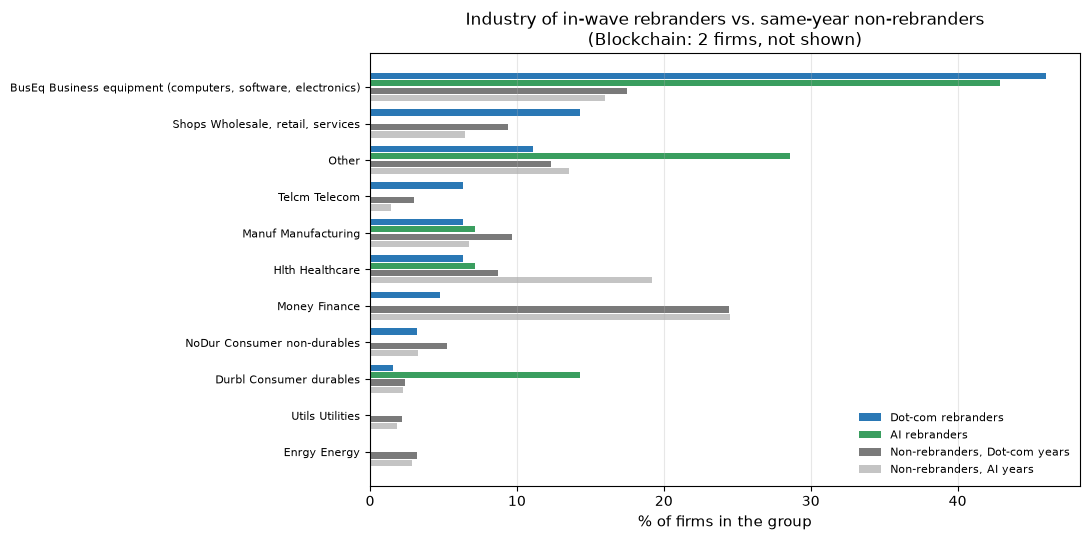

,wave,industry,n_rebranders,share_rebranders,share_same_year_others
0,Dot-com,"BusEq Business equipment (computers, software,...",29,0.460,0.175
2,Dot-com,Durbl Consumer durables,1,0.016,0.024
4,Dot-com,Hlth Healthcare,4,0.063,0.087
5,Dot-com,Manuf Manufacturing,4,0.063,0.097
6,Dot-com,Money Finance,3,0.048,0.244
7,Dot-com,NoDur Consumer non-durables,2,0.032,0.053
8,Dot-com,Other,7,0.111,0.123
9,Dot-com,"Shops Wholesale, retail, services",9,0.143,0.094
10,Dot-com,Telcm Telecom,4,0.063,0.030
16,Blockchain,Hlth Healthcare,1,0.500,0.140


In [21]:
def industry_mix(event_firms, firm_years):
    """
    Industry shares of in-wave rebranders and of same-year non-rebranders, per wave.

    Parameters
    ----------
    event_firms : pandas.DataFrame
    firm_years : pandas.DataFrame

    Returns
    -------
    pandas.DataFrame
        One row per wave and FF12 industry: counts and shares for both groups.
    """
    others = firm_years[~firm_years["permno"].isin(set(event_firms["permno"]))].copy()
    others["industry"] = others["sich"].fillna(others["sic"]).map(es.ff12_industry)
    rows = []
    for theme in themes:
        treated = event_firms[(event_firms["theme"] == theme) & (event_firms["in_wave_period"] == 1)]
        year_weights = treated["fundamentals_fyear"].fillna(treated["event_date"].dt.year).value_counts()
        control = others[others["fyear"].isin(year_weights.index)].copy()
        control["weight"] = control["fyear"].map(year_weights) / control["fyear"].map(control["fyear"].value_counts())
        control_share = control.groupby("industry")["weight"].sum() / control["weight"].sum()
        treated_counts = treated["industry"].value_counts()
        for industry in sorted(set(treated_counts.index) | set(control_share.index)):
            rows.append({"wave": theme, "industry": industry, "n_rebranders": int(treated_counts.get(industry, 0)),
                         "share_rebranders": treated_counts.get(industry, 0) / len(treated),
                         "share_same_year_others": control_share.get(industry, 0.0)})
    return pd.DataFrame(rows)


industry_table = industry_mix(event_firms, firm_years)
# each wave is compared with non-rebranders of ITS OWN years; Blockchain (2 firms) is not plotted
plot_groups = {"Dot-com rebranders": ("Dot-com", "share_rebranders", theme_colors["Dot-com"]),
               "AI rebranders": ("AI", "share_rebranders", theme_colors["AI"]),
               "Non-rebranders, Dot-com years": ("Dot-com", "share_same_year_others", "#7a7a7a"),
               "Non-rebranders, AI years": ("AI", "share_same_year_others", "#c4c4c4")}
shares = pd.DataFrame({name: industry_table[industry_table["wave"] == wave].set_index("industry")[column]
                       for name, (wave, column, _) in plot_groups.items()}).fillna(0)
shares = shares[shares.max(axis=1) >= 0.02].sort_values("Dot-com rebranders")
fig, ax = plt.subplots(figsize=(11, 5.5))
height = 0.2
for i, (name, (_, _, color)) in enumerate(plot_groups.items()):
    ax.barh([y + (1.5 - i) * height for y in range(len(shares))], shares[name] * 100, height=height - 0.03,
            color=color, label=name)
ax.set_yticks(range(len(shares)), shares.index, fontsize=8)
ax.set(title="Industry of in-wave rebranders vs. same-year non-rebranders\n(Blockchain: 2 firms, not shown)",
       xlabel="% of firms in the group", ylabel="")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(output_dir / "rq4_industry_mix.png", dpi=150)
plt.show()
industry_table[industry_table["n_rebranders"] > 0].round(3)

## Step 10: RQ3, AI vs Dot-com
**Main quantity:** the direct difference in mean CAR between the primary AI and Dot-com samples, with a
bootstrap 95% interval (each wave resampled separately) and a Welch t-test.

**One small regression** (Tutorial 4 preprocessing: `OneHotEncoder` for the theme, `StandardScaler` for the
controls), estimated with and without controls on the **same events** (those with both controls):
$$CAR_i = \alpha + \beta\,AI_i + \gamma_1\,\log MarketCap_i + \gamma_2\,Volatility_i + \varepsilon_i$$
Standard errors: HC3 and clustered by event month. Sensitivity models add ROA and R&D/assets with
`SimpleImputer(median)` (R&D is missing for many firms), or a single tech-industry dummy (FF12 business
equipment); a full set of industry dummies is not estimable with 8 AI events. With few AI events the regression is **exploratory**:
theme is also tied to era, technology and the type of issuer, so a change in β after adding controls does not
show that firm characteristics "explain" the gap.

In [22]:
rq3_themes = ["Dot-com", "AI"]       # Dot-com = reference category
rq3_data = primary[primary["theme"].isin(rq3_themes)].merge(
    event_firms[["event_id", "industry"] + compustat_columns + crsp_columns], on="event_id", how="left")
rq3_data["tech_industry"] = rq3_data["industry"].str.startswith("BusEq").astype(float)   # one dummy only (8 AI events)


def bootstrap_difference(data, outcome, group_a="AI", group_b="Dot-com", n_draws=es.N_BOOTSTRAP):
    """
    Bootstrap the difference in mean outcome between two waves (resampling within each wave).

    Parameters
    ----------
    data : pandas.DataFrame
    outcome : str
    group_a, group_b : str
    n_draws : int

    Returns
    -------
    dict
        Difference, 95% interval, bootstrap and Welch p-values.
    """
    x = data.loc[data["theme"] == group_a, outcome].dropna().to_numpy()
    y = data.loc[data["theme"] == group_b, outcome].dropna().to_numpy()
    draws = rng.choice(x, (n_draws, len(x))).mean(axis=1) - rng.choice(y, (n_draws, len(y))).mean(axis=1)
    observed = x.mean() - y.mean()
    return {"outcome": outcome, "difference": f"{group_a} - {group_b}", "n_a": len(x), "n_b": len(y),
            "estimate": observed, "ci_low": np.percentile(draws, 2.5), "ci_high": np.percentile(draws, 97.5),
            "boot_pvalue": (np.abs(draws - observed) >= abs(observed)).mean(),
            "welch_pvalue": stats.ttest_ind(x, y, equal_var=False).pvalue}


theme_differences = pd.DataFrame([bootstrap_difference(rq3_data, m) for m in [es.PRIMARY_MEASURE] + es.SECONDARY_MEASURES])
theme_differences.round(4)

,outcome,difference,n_a,n_b,estimate,ci_low,ci_high,boot_pvalue,welch_pvalue
0,car_m1_p1,AI - Dot-com,8,37,-0.0445,-0.1895,0.1171,0.5681,0.5953
1,car_m5_p5,AI - Dot-com,8,37,-0.1923,-0.4017,0.0288,0.0823,0.1258
2,cav_m1_p1,AI - Dot-com,8,37,0.3573,-2.6220,3.4855,0.8212,0.8337


In [23]:
def build_design(data, controls, impute=False):
    """
    Build the RQ3 design matrix with the Tutorial 4 preprocessing pipeline.

    Parameters
    ----------
    data : pandas.DataFrame
    controls : list of str
    impute : bool
        Impute missing controls with the median (sensitivity model only).

    Returns
    -------
    pandas.DataFrame
        Design matrix incl. a constant.
    """
    transformers = [("theme", OneHotEncoder(categories=[rq3_themes], drop="first", sparse_output=False), ["theme"])]
    if controls:
        steps = [SimpleImputer(strategy="median"), StandardScaler()] if impute else [StandardScaler()]
        transformers.append(("num", make_pipeline(*steps), controls))
    design = ColumnTransformer(transformers, verbose_feature_names_out=False).fit_transform(data)
    return sm.add_constant(design.astype(float))


def fit_rq3_models(data, outcome):
    """
    Estimate the unadjusted and adjusted AI-vs-Dot-com models on the same events, plus the sensitivity model.

    Parameters
    ----------
    data : pandas.DataFrame
    outcome : str

    Returns
    -------
    pandas.DataFrame
        AI coefficient with HC3 and month-clustered p-values.
    """
    core_controls = ["log_market_cap", "pre_event_volatility"]
    complete = data.dropna(subset=[outcome] + core_controls).reset_index(drop=True)
    specs = [("(1) AI dummy only, all events", data.dropna(subset=[outcome]).reset_index(drop=True), [], False),
             ("(2) AI dummy only, events with controls", complete, [], False),
             ("(3) + log market cap, volatility", complete, core_controls, False),
             ("(4) sensitivity: + ROA, R&D/assets (median-imputed)", complete, core_controls + ["roa", "rd_to_assets"], True),
             ("(5) sensitivity: + tech-industry dummy (FF12 BusEq)", complete, core_controls + ["tech_industry"], False)]
    rows = []
    for label, sample, controls, impute in specs:
        design, y = build_design(sample, controls, impute), sample[outcome].astype(float)
        hc3 = sm.OLS(y, design).fit(cov_type="HC3")
        clustered = sm.OLS(y, design).fit(cov_type="cluster",
                                          cov_kwds={"groups": pd.factorize(sample["event_month"])[0]})
        rows.append({"outcome": outcome, "model": label, "coef_AI": hc3.params["theme_AI"],
                     "hc3_se": hc3.bse["theme_AI"], "hc3_pvalue": hc3.pvalues["theme_AI"],
                     "cluster_pvalue": clustered.pvalues["theme_AI"], "n_obs": int(hc3.nobs),
                     "n_AI": int((sample["theme"] == "AI").sum()), "r_squared": hc3.rsquared})
    return pd.DataFrame(rows)


regressions = pd.concat([fit_rq3_models(rq3_data, m) for m in [es.PRIMARY_MEASURE, "car_m5_p5"]], ignore_index=True)
regressions.round(4)

,outcome,model,coef_AI,hc3_se,hc3_pvalue,cluster_pvalue,n_obs,n_AI,r_squared
0,car_m1_p1,"(1) AI dummy only, all events",-0.0445,0.0862,0.6055,0.5620,45,8,0.0047
1,car_m1_p1,"(2) AI dummy only, events with controls",-0.0445,0.0862,0.6055,0.5620,45,8,0.0047
2,car_m1_p1,"(3) + log market cap, volatility",-0.0756,0.1137,0.5063,0.4203,45,8,0.1108
3,car_m1_p1,"(4) sensitivity: + ROA, R&D/assets (median-imp...",-0.0599,0.1191,0.6152,0.5508,45,8,0.1216
4,car_m1_p1,(5) sensitivity: + tech-industry dummy (FF12 B...,-0.0779,0.1003,0.4377,0.3413,45,8,0.2870
5,car_m5_p5,"(1) AI dummy only, all events",-0.1923,0.1230,0.1181,0.0797,45,8,0.0501
6,car_m5_p5,"(2) AI dummy only, events with controls",-0.1923,0.1230,0.1181,0.0797,45,8,0.0501
7,car_m5_p5,"(3) + log market cap, volatility",-0.1936,0.1259,0.1240,0.0754,45,8,0.1188
8,car_m5_p5,"(4) sensitivity: + ROA, R&D/assets (median-imp...",-0.1564,0.1393,0.2614,0.1879,45,8,0.1349
9,car_m5_p5,(5) sensitivity: + tech-industry dummy (FF12 B...,-0.1954,0.1391,0.1601,0.1073,45,8,0.1810


In [24]:
# Influence check with the Tutorial-4 IsolationForest (trained on the outcomes -> diagnostic only)
inputs = rq3_data[[es.PRIMARY_MEASURE, "car_m5_p5"]]
rq3_data["isolation_flag"] = IsolationForest(random_state=random_state, contamination=0.05) \
    .fit_predict(inputs.fillna(inputs.median())) == -1
without_flagged = bootstrap_difference(rq3_data[~rq3_data["isolation_flag"]], es.PRIMARY_MEASURE)
print("AI - Dot-com CAR[-1,+1] without the IsolationForest-flagged events:", round(without_flagged["estimate"], 4),
      "| flagged:", rq3_data.loc[rq3_data["isolation_flag"], "new_name"].tolist())

AI - Dot-com CAR[-1,+1] without the IsolationForest-flagged events: -0.0149 | flagged: ['FINET COM INC', 'GETGO MAIL COM INC', 'ILIFE COM INC']


## Step 11: Confirmatory tests (Holm correction) and export
The **confirmatory family** has three tests, fixed before looking at any returns:
1. Dot-com mean CAR[−1,+1] = 0 (bootstrap p-value);
2. AI mean CAR[−1,+1] = 0 (t-test; n < 10 does not support a bootstrap);
3. AI − Dot-com difference in mean CAR[−1,+1] = 0 (bootstrap p-value).

Holm's (1979) step-down correction controls the family-wise error rate. Every other test in the project is
labelled exploratory.

In [25]:
def row_of(sample, measure):
    """
    Return one row of the event-study summary.

    Parameters
    ----------
    sample, measure : str

    Returns
    -------
    pandas.Series
    """
    return event_study_summary[(event_study_summary["sample"] == sample) & (event_study_summary["measure"] == measure)].iloc[0]


dotcom_row, ai_row = row_of("Dot-com (primary)", es.PRIMARY_MEASURE), row_of("AI (primary)", es.PRIMARY_MEASURE)
difference_row = theme_differences[theme_differences["outcome"] == es.PRIMARY_MEASURE].iloc[0]
confirmatory = pd.DataFrame([
    {"test": "Dot-com mean CAR[-1,+1] = 0", "estimate": dotcom_row["mean"], "n": dotcom_row["n"],
     "p_value": dotcom_row.get("boot_pvalue", dotcom_row["t_pvalue"]), "p_source": "bootstrap"},
    {"test": "AI mean CAR[-1,+1] = 0", "estimate": ai_row["mean"], "n": ai_row["n"],
     "p_value": ai_row["t_pvalue"], "p_source": "t-test"},
    {"test": "AI - Dot-com mean CAR[-1,+1] = 0", "estimate": difference_row["estimate"],
     "n": difference_row["n_a"] + difference_row["n_b"], "p_value": difference_row["boot_pvalue"], "p_source": "bootstrap"},
])
confirmatory["holm_pvalue"] = es.holm_adjust(confirmatory["p_value"])
confirmatory.round(4)

,test,estimate,n,p_value,p_source,holm_pvalue
0,"Dot-com mean CAR[-1,+1] = 0",0.0869,37,0.0410,bootstrap,0.123
1,"AI mean CAR[-1,+1] = 0",0.0423,8,0.5604,t-test,1.000
2,"AI - Dot-com mean CAR[-1,+1] = 0",-0.0445,45,0.5681,bootstrap,1.000


In [26]:
def export_results(tables, path):
    """
    Write result tables to one Excel workbook (one sheet per table).

    Parameters
    ----------
    tables : dict of pandas.DataFrame
        Sheet name -> table.
    path : pathlib.Path
    """
    with pd.ExcelWriter(path) as writer:
        for sheet_name, table in tables.items():
            table.to_excel(writer, sheet_name=sheet_name[:31], index=False)
    print("results written to", path)


event_level = event_firms.merge(cars[["event_id", "benchmark_used", "descriptive_only", "day0_date"]
                                     + [c for c in cars.columns if c[:3] in ("car", "sca", "cav")]],
                                on="event_id", how="left")
export_results({
    "A_event_level": event_level,
    "B_theme_year": theme_year,
    "sample_flow": sample_flow,
    "rq1_wave_summary": wave_summary,
    "eda_correlation": corr_matrix.reset_index(),
    "rq2_event_study": event_study_summary,
    "rq2_blockchain_cases": blockchain_cases,
    "rq2_leave_one_out": pd.concat([loo_dotcom.assign(theme="Dot-com"), loo_ai.assign(theme="AI")]),
    "rq2_daily_abnormal": abnormal,
    "rq2_estimation": estimates,
    "rq3_difference": theme_differences,
    "rq3_regressions": regressions,
    "rq4_characteristics": characteristics,
    "rq4_industry": industry_table,
    "confirmatory_holm": confirmatory,
    "data_quality": data_quality,
}, output_dir / "core_analysis_results.xlsx")
cars.to_csv(processed_dir / "rename_cars.csv", index=False)

results written to /Users/chunhanliao/Documents/FS_MADS/1_IntroDA/Group Project/IDA_Group7_whats_in_a_buzzword_submission/output/core_analysis_results.xlsx


## Summary of results (numbers from the run above)
**Sample.** 97 thematic renames detected (Dot-com 79, AI 14, Blockchain 4); 79 fall in the wave periods. 65
in-wave events have a verified public announcement date (grade A/B). The **primary sample** (grade A/B, wave
years, cosmetic renames and pivots) has 49 events: Dot-com 39 (37 with a complete CAR[−1,+1]), AI 8,
Blockchain 2.

**RQ1: Prevalence (CRSP effective year).** Dot-com: 63 in-wave renames, 0.98 per 1,000 listed firms per year,
peak 4.15 in 1999, 2.5% of all name changes. AI: 14, 0.52 per 1,000, rising to 1.13 in 2025, 1.3%. Blockchain: 2
in-wave renames (0.09 per 1,000, 0.3%). These counts use the CRSP effective year, so they do not depend on the announcement dates.

**RQ2: Announcement response (primary outcome CAR[−1,+1]).**
* **Dot-com (n = 37):** mean **+8.7%** (95% CI −0.1% to +17.5%), median +6.6%, 62% positive; bootstrap p = 0.04,
  month-clustered p = 0.02, t-test p = 0.053, BMP p = 0.10, sign test p = 0.19. After the Holm correction over
  the three confirmatory tests, p = 0.12. CAR[−5,+5] = +16.6% (bootstrap p = 0.003). Abnormal volume +4.2 log
  points (p < 0.001).
* **AI (n = 8):** mean +4.2%, 95% CI −12.1% to +20.6% (MDE ≈ 23%): uninformative, neither a premium nor its
  absence can be shown. Abnormal volume +4.5 log points (p = 0.02).
* **Blockchain case studies (in wave):** Riot Blockchain +14.6% over [−1,+1] (SQ p = 0.03) and +80.6% over
  [−5,+5] (SQ p < 0.01); Long Blockchain +188% over [−1,+1] (SQ p < 0.01). Outside the wave (appendix): Bitcoin
  Depot (de-SPAC) no reaction; American Bitcoin (reverse merger) +181% over [−1,+1].

**RQ3: AI − Dot-com.** CAR[−1,+1]: −4.5 pp (95% CI −19.0 to +11.7, p = 0.57); CAR[−5,+5]: −19.2 pp (CI −40.2 to
+2.9, p = 0.08). Adding pre-event size and volatility leaves the gap about the same (−7.6 pp, p = 0.51), and so
does a single tech-industry dummy (−7.8 pp, p = 0.44). The comparison is too imprecise to rank the waves.

**RQ4: Who rebrands?** Against non-rebranders of the same fiscal years, in-wave Dot-com rebranders are smaller
(standardised difference −1.15), loss-making (−0.83), cash-rich (+0.84) and R&D-intensive (+0.49); AI rebranders
are even smaller (−1.85) and more loss-making (−1.75). Across waves, AI/Blockchain adopters have lower ROA
(Kruskal-Wallis p = 0.01) and CAPEX (p = 0.04) than Dot-com adopters.

**RQ4: Industry (Fama-French 12).** Buzzword adopters are over-represented in business equipment (computers,
software, electronics): 46% of in-wave Dot-com rebranders vs. 18% of same-year non-rebranders, and 43% of AI
rebranders vs. 16%. Finance is under-represented among Dot-com rebranders (5% vs. 24%). Still, more than half of
the Dot-com rebranders came from outside tech (retail and services 14%, telecom, healthcare, manufacturing):
the label was adopted across the economy. For SPAC shells (SIC 6799) the merged company's Compustat SIC is used.

**Limitations.** Small AI and Blockchain samples; Dot-com evidence rests on the mean of a skewed distribution and
is not significant after the Holm correction; deal-type and date codes for 27 events are flagged for a second
check by a teammate. Sensitivity and confounding analyses: notebook 07.